# MBPO, one update at a time — a small worked example (Group 18)

This notebook shows **how MBPO updates its model, its value function and its policy**, on an example small
enough that every number can be printed and checked by hand. It runs on a CPU in about a minute and needs only
`numpy`, `torch` and `matplotlib`.

The full-scale implementation (HalfCheetah-v5, 7-member ensemble, 256-unit SAC, GPU) is in the `mbpo/` package
and `notebooks/MBPO_HalfCheetah_Kaggle.ipynb`; it uses exactly the same equations as below, just bigger networks.

**MBPO** (Janner et al., 2019) is a **model-based, actor-critic** algorithm. One iteration:

1. **Train the model** $\hat p_\theta(s', r \mid s, a)$ by maximum likelihood on all real data $\mathcal D_{env}$.
2. **Act in the real environment** with the current policy $\pi_\phi$, store transitions in $\mathcal D_{env}$.
3. **Branch short rollouts**: start from real states, simulate $k$ steps in the model, store them in $\mathcal D_{model}$.
4. **Update the policy** with Soft Actor-Critic (SAC), on batches drawn mostly (95%) from $\mathcal D_{model}$.

Contents: (0) a toy environment · (1) real data · (2) fitting the probabilistic ensemble · (3) one branched rollout ·
(4) **one SAC update, step by step** (critic, actor, temperature, target network) · (5) the full loop on the toy
problem vs. model-free SAC · (6) results of the real HalfCheetah run.

In [1]:
import math, copy
import numpy as np
import torch, torch.nn as nn, torch.nn.functional as F
import matplotlib.pyplot as plt

torch.manual_seed(0); np.random.seed(0)
torch.set_printoptions(precision=4, sci_mode=False)
np.set_printoptions(precision=4, suppress=True)

## 0. A toy "cheetah" we can reason about

HalfCheetah rewards forward speed minus a control cost, $r_t = \frac{x_{t+1}-x_t}{\Delta t} - 0.1\,\lVert a_t\rVert^2$,
and hides the $x$-position from the agent. Our toy keeps exactly that structure in one dimension:

* observation $s = v$ (velocity; position $x$ is hidden), action $a \in [-1, 1]$ (a "torque"),
* dynamics $v' = 0.8\,v + a + \varepsilon,\ \varepsilon \sim \mathcal N(0, 0.05^2)$, and $x' = x + \Delta t\, v'$,
* reward $r = \frac{x'-x}{\Delta t} - 0.1a^2 = v' - 0.1a^2$, episodes are truncated after 50 steps (no terminal states).

The best policy pushes forward ($a = 1$), reaching $v \to 5$ and a return of about 220; a random policy gets about 0.

In [2]:
class ToyCheetah:
    T, dt = 50, 0.1
    def reset(self, rng):
        self.t, self.x, self.v = 0, 0.0, rng.normal(0, 0.1)
        return np.array([self.v], dtype=np.float32)
    def step(self, a, rng):
        a = float(np.clip(a, -1, 1))
        v_new = 0.8 * self.v + a + rng.normal(0, 0.05)
        x_new = self.x + self.dt * v_new
        r = (x_new - self.x) / self.dt - 0.1 * a ** 2
        self.x, self.v, self.t = x_new, v_new, self.t + 1
        return np.array([v_new], dtype=np.float32), r, False, self.t >= self.T   # obs, reward, terminated, truncated

env, rng = ToyCheetah(), np.random.default_rng(0)

## 1. Real data $\mathcal D_{env}$ (step 2 of MBPO)
MBPO starts with a few random-policy episodes, exactly like our HalfCheetah run (5000 random steps there, 400 here).

In [3]:
def collect(policy, n_steps):
    data, obs = [], env.reset(rng)
    for _ in range(n_steps):
        a = policy(obs)
        nxt, r, term, trunc = env.step(a, rng)
        data.append((obs, np.array([a], dtype=np.float32), r, nxt, float(term)))
        obs = env.reset(rng) if (term or trunc) else nxt
    s, a, r, s2, d = map(np.array, zip(*data))
    return {"obs": torch.tensor(s), "act": torch.tensor(a), "rew": torch.tensor(r, dtype=torch.float32),
            "next_obs": torch.tensor(s2), "done": torch.tensor(d, dtype=torch.float32)}

D_env = collect(lambda o: rng.uniform(-1, 1), 400)
print("first 5 real transitions (s, a, r, s'):")
for i in range(5):
    print(f"  s={D_env['obs'][i].item():+.3f}  a={D_env['act'][i].item():+.3f}  "
          f"r={D_env['rew'][i].item():+.3f}  s'={D_env['next_obs'][i].item():+.3f}")

first 5 real transitions (s, a, r, s'):
  s=+0.013  a=-0.460  r=-0.440  s'=-0.418
  s=-0.418  a=-0.967  r=-1.422  s'=-1.328
  s=-1.328  a=+0.826  r=-0.240  s'=-0.172
  s=-0.172  a=+0.459  r=+0.265  s'=+0.286
  s=+0.286  a=+0.870  r=+0.992  s'=+1.068


## 2. Fitting the probabilistic ensemble (step 1 of MBPO)

Each of $E$ networks outputs a Gaussian over the **reward and the state change** $y = [\,r,\ s'-s\,]$:
$\hat p_{\theta_e}(y \mid s,a) = \mathcal N\big(\mu_{\theta_e}(s,a),\ \operatorname{diag}\sigma^2_{\theta_e}(s,a)\big)$.
It is trained by maximum likelihood, i.e. by minimising the Gaussian negative log-likelihood

$$\mathcal L(\theta_e) = \frac1N\sum_{n}\Big[(\mu_{\theta_e}(s_n,a_n) - y_n)^\top \Sigma_{\theta_e}^{-1}(\mu_{\theta_e}(s_n,a_n) - y_n) + \log\det\Sigma_{\theta_e}(s_n,a_n)\Big].$$

* the **variance** captures *aleatoric* noise (our $\varepsilon$);
* the **ensemble** (each member trained on its own bootstrap resample of $\mathcal D_{env}$) captures *epistemic*
  uncertainty — members disagree where data is scarce;
* $\log\sigma^2$ is softly clamped between learned bounds, exactly as in the full implementation.

In [4]:
class Ensemble(nn.Module):
    def __init__(self, E=3, in_dim=2, out_dim=2, hidden=32):
        super().__init__()
        self.E, self.out_dim = E, out_dim
        self.nets = nn.ModuleList([nn.Sequential(nn.Linear(in_dim, hidden), nn.SiLU(),
                                                 nn.Linear(hidden, hidden), nn.SiLU(),
                                                 nn.Linear(hidden, 2 * out_dim)) for _ in range(E)])
        self.max_logvar = nn.Parameter(torch.full((out_dim,), 0.5))
        self.min_logvar = nn.Parameter(torch.full((out_dim,), -10.0))
        self.elites = list(range(E))
    def forward(self, s, a):                        # -> mean, logvar of shape (E, B, out_dim)
        x = torch.cat([s, a], -1)
        out = torch.stack([net(x) for net in self.nets])
        mean, logvar = out[..., :self.out_dim], out[..., self.out_dim:]
        logvar = self.max_logvar - F.softplus(self.max_logvar - logvar)
        logvar = self.min_logvar + F.softplus(logvar - self.min_logvar)
        return mean, logvar

def targets(d):
    return torch.cat([d["rew"][:, None], d["next_obs"] - d["obs"]], -1)   # y = [r, s'-s]

def nll(model, d, idx):
    mean, logvar = model(d["obs"][idx], d["act"][idx])             # idx: (E, B), one resample per member
    y = targets(d)[idx]
    return (((mean - y) ** 2) * torch.exp(-logvar) + logvar).mean((1, 2)).sum() \
        + 0.01 * (model.max_logvar.sum() - model.min_logvar.sum())

def fit(model, d, epochs=150, batch=64, num_elites=2, verbose=True):
    opt = torch.optim.Adam(model.parameters(), lr=3e-3)
    n = d["obs"].shape[0]; perm = torch.randperm(n); n_hold = n // 5
    hold, train = perm[:n_hold], perm[n_hold:]
    boot = train[torch.randint(len(train), (model.E, len(train)))]   # bootstrap resample per member
    for ep in range(epochs):
        shuffled = boot[:, torch.randperm(boot.shape[1])]
        for i in range(0, shuffled.shape[1], batch):
            loss = nll(model, d, shuffled[:, i:i + batch])
            opt.zero_grad(); loss.backward(); opt.step()
        if verbose and (ep % 50 == 0 or ep == epochs - 1):
            with torch.no_grad():
                hold_nll = nll(model, d, hold.expand(model.E, -1)).item() / model.E
            print(f"epoch {ep:3d}  train NLL/member {loss.item() / model.E:+.3f}   holdout NLL/member {hold_nll:+.3f}")
    with torch.no_grad():                            # elites = members with the lowest holdout error
        mean, _ = model(d["obs"][hold], d["act"][hold])
        mse = ((mean - targets(d)[hold]) ** 2).mean((1, 2))
    model.elites = torch.argsort(mse)[:num_elites].tolist()
    return mse

model = Ensemble()
mse = fit(model, D_env)
print("holdout MSE per member:", mse.numpy(), "-> elites:", model.elites)

epoch   0  train NLL/member +0.999   holdout NLL/member +0.936
epoch  50  train NLL/member -10.165   holdout NLL/member -8.492


epoch 100  train NLL/member -9.997   holdout NLL/member -8.575
epoch 149  train NLL/member -10.082   holdout NLL/member -8.526
holdout MSE per member: [0.0032 0.0033 0.0033] -> elites: [0, 2]


**One prediction.** For a single $(s, a)$ every member predicts a mean and a standard deviation for $[r, s'-s]$.
The true process here is $v' - v = -0.2v + a$ and $r = v' - 0.1a^2$ with noise std 0.05:

In [5]:
s, a = torch.tensor([[1.0]]), torch.tensor([[0.5]])
v_next = 0.8 * 1.0 + 0.5
print(f"true:      r = {v_next - 0.1 * 0.25:+.3f}   s'-s = {v_next - 1.0:+.3f}   (noise std 0.05)")
with torch.no_grad():
    mean, logvar = model(s, a)
for e in range(model.E):
    m, sd = mean[e, 0], (0.5 * logvar[e, 0]).exp()
    print(f"member {e}: r = {m[0]:+.3f} ± {sd[0]:.3f}   s'-s = {m[1]:+.3f} ± {sd[1]:.3f}"
          + ("   (elite)" if e in model.elites else ""))

# far outside the data (v = 8 was never visited) the members disagree: epistemic uncertainty
with torch.no_grad():
    mean_far, _ = model(torch.tensor([[8.0]]), torch.tensor([[1.0]]))
print("\nunseen state v=8, a=1: true s'-s =", 0.8 * 8 + 1 - 8, "| members predict", mean_far[:, 0, 1].numpy())

true:      r = +1.275   s'-s = +0.300   (noise std 0.05)
member 0: r = +1.266 ± 0.047   s'-s = +0.285 ± 0.045   (elite)
member 1: r = +1.261 ± 0.046   s'-s = +0.288 ± 0.046
member 2: r = +1.259 ± 0.047   s'-s = +0.283 ± 0.050   (elite)

unseen state v=8, a=1: true s'-s = -0.5999999999999996 | members predict [ 0.0685 -0.2784 -0.2946]


## 3. One short branched rollout (step 3 of MBPO)

We start from **real** states sampled from $\mathcal D_{env}$ and roll the *current policy* forward for $k$ steps
inside the model. At every step each start state uses a **randomly chosen elite member**, and we sample from its
Gaussian: $\;y \sim \mathcal N(\mu_e, \sigma_e^2),\ s' = s + y_{1:},\ r = y_0$. Each simulated step becomes a
transition in $\mathcal D_{model}$. Because branches start from real states, $k$ can stay small and model errors
cannot compound for long (HalfCheetah uses $k = 1$).

First we need a policy. SAC's policy is a **tanh-squashed Gaussian**: $a = \tanh(u),\ u = \mu_\phi(s) + \sigma_\phi(s)\,\xi,\ \xi\sim\mathcal N(0,1)$,
with log-density $\log\pi(a|s) = \log\mathcal N(u;\mu,\sigma^2) - \log(1-\tanh^2u)$.

In [6]:
class Actor(nn.Module):
    def __init__(self, obs_dim=1, act_dim=1, hidden=32):
        super().__init__()
        self.trunk = nn.Sequential(nn.Linear(obs_dim, hidden), nn.ReLU(), nn.Linear(hidden, hidden), nn.ReLU())
        self.mu, self.log_std = nn.Linear(hidden, act_dim), nn.Linear(hidden, act_dim)
    def dist(self, s):
        h = self.trunk(s)
        return self.mu(h), self.log_std(h).clamp(-20, 2)
    def forward(self, s, deterministic=False, xi=None):
        mu, log_std = self.dist(s)
        std = log_std.exp()
        if xi is None:
            xi = torch.zeros_like(mu) if deterministic else torch.randn_like(mu)
        u = mu + std * xi                                      # reparameterisation trick
        a = torch.tanh(u)
        log_prob = (-0.5 * xi ** 2 - log_std - 0.5 * math.log(2 * math.pi)).sum(-1) \
            - (2 * (math.log(2) - u - F.softplus(-2 * u))).sum(-1)    # = log N(u) - log(1 - tanh(u)^2)
        return a, log_prob

actor = Actor()

@torch.no_grad()
def model_rollout(model, actor, start_obs, k, verbose=False):
    out, s = [], start_obs
    for step in range(k):
        a, _ = actor(s)
        mean, logvar = model(s, a)
        member = torch.tensor(model.elites)[torch.randint(len(model.elites), (s.shape[0],))]
        y = mean + torch.randn_like(mean) * (0.5 * logvar).exp()
        y = y[member, torch.arange(s.shape[0])]
        r, s_next = y[:, 0], s + y[:, 1:]
        out.append({"obs": s, "act": a, "rew": r, "next_obs": s_next, "done": torch.zeros_like(r)})
        if verbose:
            for i in range(s.shape[0]):
                print(f"  branch {i} step {step}: s={s[i].item():+.3f}  a={a[i].item():+.3f}  "
                      f"member={member[i].item()}  ->  r̂={r[i].item():+.3f}  ŝ'={s_next[i].item():+.3f}")
        s = s_next
    return {key: torch.cat([o[key] for o in out]) for key in out[0]}

starts = D_env["obs"][torch.randint(len(D_env["obs"]), (3,))]
print(f"3 branches of length k=2 from real states {starts.flatten().numpy()}:")
D_model = model_rollout(model, actor, starts, k=2, verbose=True)
print(f"\n-> {len(D_model['obs'])} synthetic transitions added to D_model "
      "(the HalfCheetah run adds 100,000 every 250 env steps)")

3 branches of length k=2 from real states [-0.2141  1.2891 -2.4422]:
  branch 0 step 0: s=-0.214  a=+0.675  member=2  ->  r̂=+0.458  ŝ'=+0.585
  branch 1 step 0: s=+1.289  a=+0.722  member=2  ->  r̂=+1.633  ŝ'=+1.768
  branch 2 step 0: s=-2.442  a=-0.159  member=2  ->  r̂=-2.102  ŝ'=-2.062
  branch 0 step 1: s=+0.585  a=-0.902  member=0  ->  r̂=-0.502  ŝ'=-0.382
  branch 1 step 1: s=+1.768  a=+0.784  member=2  ->  r̂=+2.129  ŝ'=+2.182
  branch 2 step 1: s=-2.062  a=-0.352  member=0  ->  r̂=-2.003  ŝ'=-1.970

-> 6 synthetic transitions added to D_model (the HalfCheetah run adds 100,000 every 250 env steps)


## 4. One SAC update, step by step (step 4 of MBPO)

SAC maximises reward **plus entropy**, $J(\pi)=\mathbb E\big[\sum_t \gamma^t\,(r_t + \alpha\,\mathcal H(\pi(\cdot|s_t)))\big]$,
with four sets of parameters: twin critics $Q_{w_1}, Q_{w_2}$, slowly-moving target critics $Q_{\bar w_1}, Q_{\bar w_2}$,
the actor $\pi_\phi$ and the temperature $\alpha$.

In MBPO each mini-batch mixes real and model data: $5\%$ from $\mathcal D_{env}$ and $95\%$ from $\mathcal D_{model}$.
To keep the arithmetic visible we do the update on **one transition** taken from the model rollout above
(learning rates are larger than usual so that the change is clearly visible after a single step).

In [7]:
class Critic(nn.Module):                               # one Q-network; SAC uses two of them
    def __init__(self, obs_dim=1, act_dim=1, hidden=32):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(obs_dim + act_dim, hidden), nn.ReLU(),
                                 nn.Linear(hidden, hidden), nn.ReLU(), nn.Linear(hidden, 1))
    def forward(self, s, a):
        return self.net(torch.cat([s, a], -1)).squeeze(-1)

torch.manual_seed(1)
q1, q2 = Critic(), Critic()
q1_targ, q2_targ = copy.deepcopy(q1), copy.deepcopy(q2)
log_alpha = torch.tensor(0.0, requires_grad=True)       # alpha = 1 at the start, as in our runs
gamma, tau, target_entropy = 0.9, 0.005, -1.0           # target entropy = -|A|
q_opt = torch.optim.Adam(list(q1.parameters()) + list(q2.parameters()), lr=1e-2)
pi_opt = torch.optim.Adam(actor.parameters(), lr=1e-2)
alpha_opt = torch.optim.Adam([log_alpha], lr=1e-2)

i = 0
s, a, r, s2, d = (D_model[k][i:i + 1] for k in ("obs", "act", "rew", "next_obs", "done"))
print(f"transition from D_model:  s = {s.item():+.4f}   a = {a.item():+.4f}   r = {r.item():+.4f}   s' = {s2.item():+.4f}   done = {d.item():.0f}")

transition from D_model:  s = -0.2141   a = +0.6747   r = +0.4583   s' = +0.5846   done = 0


### 4a. Critic (value) update

Soft Bellman target, using a **fresh action from the current policy** at $s'$ and the **minimum** of the two target critics
(clipped double-Q, against over-estimation):

$$a' \sim \pi_\phi(\cdot|s'),\qquad y = r + \gamma\,(1-d)\Big[\min_{j=1,2} Q_{\bar w_j}(s',a') - \alpha \log\pi_\phi(a'|s')\Big]$$

$$\mathcal L_Q(w_i) = \big(Q_{w_i}(s,a) - y\big)^2,\quad i = 1, 2 .$$

In [8]:
alpha = log_alpha.exp().item()
xi_next = torch.tensor([[0.3]])                      # fix the noise so the numbers are reproducible
with torch.no_grad():
    a2, logp2 = actor(s2, xi=xi_next)
    qt1, qt2 = q1_targ(s2, a2), q2_targ(s2, a2)
    y = r + gamma * (1 - d) * (torch.min(qt1, qt2) - alpha * logp2)
print(f"a' = tanh(mu(s') + sigma(s')*xi) = {a2.item():+.4f}     log pi(a'|s') = {logp2.item():+.4f}")
print(f"target critics:  Q1'(s',a') = {qt1.item():+.4f}   Q2'(s',a') = {qt2.item():+.4f}   -> min = {torch.min(qt1, qt2).item():+.4f}")
print(f"y = r + gamma*(1-d)*(min Q' - alpha*log pi)")
print(f"  = {r.item():+.4f} + {gamma}*(1-{d.item():.0f})*({torch.min(qt1, qt2).item():+.4f} - {alpha:.3f}*({logp2.item():+.4f}))  =  {y.item():+.4f}")

q1_before, q2_before = q1(s, a).item(), q2(s, a).item()
loss_q = ((q1(s, a) - y) ** 2).mean() + ((q2(s, a) - y) ** 2).mean()
q_opt.zero_grad(); loss_q.backward(); q_opt.step()
q1_after, q2_after = q1(s, a).item(), q2(s, a).item()
print(f"\ncritic loss = (Q1-y)^2 + (Q2-y)^2 = {loss_q.item():.4f}")
print(f"Q1(s,a): {q1_before:+.4f} -> {q1_after:+.4f}     (target y = {y.item():+.4f})")
print(f"Q2(s,a): {q2_before:+.4f} -> {q2_after:+.4f}")
print("both critics moved towards the target ✓" if abs(q1_after - y.item()) < abs(q1_before - y.item()) else "")

a' = tanh(mu(s') + sigma(s')*xi) = +0.4253     log pi(a'|s') = -0.9285
target critics:  Q1'(s',a') = -0.0083   Q2'(s',a') = -0.0334   -> min = -0.0334
y = r + gamma*(1-d)*(min Q' - alpha*log pi)
  = +0.4583 + 0.9*(1-0)*(-0.0334 - 1.000*(-0.9285))  =  +1.2640

critic loss = (Q1-y)^2 + (Q2-y)^2 = 3.3670
Q1(s,a): -0.0184 -> +0.0909     (target y = +1.2640)
Q2(s,a): -0.0485 -> +0.1430
both critics moved towards the target ✓


### 4b. Actor (policy) update

The policy is pushed towards actions with **high Q-value and high entropy**. With the reparameterisation
$\tilde a = \tanh(\mu_\phi(s) + \sigma_\phi(s)\,\xi)$ the gradient flows through the action into the critic:

$$\mathcal L_\pi(\phi) = \alpha\log\pi_\phi(\tilde a|s) - \min_{j} Q_{w_j}(s,\tilde a).$$

The critics are frozen during this step — only $\phi$ changes.

In [9]:
xi = torch.tensor([[-0.2]])                       # fixed noise, so before/after are comparable
def actor_objective():
    a_new, logp = actor(s, xi=xi)
    q_new = torch.min(q1(s, a_new), q2(s, a_new))
    return a_new, logp, q_new, (log_alpha.exp().detach() * logp - q_new).mean()

with torch.no_grad():
    mu0, log_std0 = actor.dist(s)
a_new, logp, q_new, loss_pi = actor_objective()
print(f"before: mu(s) = {mu0.item():+.4f}  sigma(s) = {log_std0.exp().item():.4f}  a~ = {a_new.item():+.4f}  "
      f"log pi = {logp.item():+.4f}  min Q(s,a~) = {q_new.item():+.4f}")
print(f"actor loss = alpha*log pi - min Q = {alpha:.3f}*({logp.item():+.4f}) - ({q_new.item():+.4f}) = {loss_pi.item():+.4f}")

for p in list(q1.parameters()) + list(q2.parameters()):
    p.requires_grad_(False)
pi_opt.zero_grad(); loss_pi.backward(); pi_opt.step()
for p in list(q1.parameters()) + list(q2.parameters()):
    p.requires_grad_(True)

with torch.no_grad():
    mu1, log_std1 = actor.dist(s)
    a_new1, logp1, q_new1, loss_pi1 = actor_objective()
print(f"after:  mu(s) = {mu1.item():+.4f}  sigma(s) = {log_std1.exp().item():.4f}  a~ = {a_new1.item():+.4f}  "
      f"log pi = {logp1.item():+.4f}  min Q(s,a~) = {q_new1.item():+.4f}")
print(f"actor loss: {loss_pi.item():+.4f} -> {loss_pi1.item():+.4f}  (lower is better ✓)")

before: mu(s) = +0.1682  sigma(s) = 1.2738  a~ = -0.0863  log pi = -1.1735  min Q(s,a~) = -0.0055
actor loss = alpha*log pi - min Q = 1.000*(-1.1735) - (-0.0055) = -1.1679
after:  mu(s) = +0.2507  sigma(s) = 1.4733  a~ = -0.0439  log pi = -1.3245  min Q(s,a~) = +0.0023
actor loss: -1.1679 -> -1.3269  (lower is better ✓)


### 4c. Temperature update and 4d. target networks

The temperature $\alpha$ is tuned automatically so that the policy entropy stays near a target $\bar{\mathcal H}$
(we use $-|\mathcal A|$ here; MBPO uses $-3$ for HalfCheetah):

$$\mathcal L(\alpha) = -\log\alpha\,\big(\log\pi_\phi(\tilde a|s) + \bar{\mathcal H}\big).$$

If the policy is *more* random than the target ($-\log\pi > \bar{\mathcal H}$) the gradient lowers $\alpha$, and vice versa.
Finally the target critics trail the critics by Polyak averaging, $\bar w \leftarrow \tau w + (1-\tau)\bar w$, which keeps $y$ stable.

In [10]:
alpha_before = log_alpha.exp().item()
loss_alpha = -(log_alpha * (logp.detach() + target_entropy)).mean()
alpha_opt.zero_grad(); loss_alpha.backward(); alpha_opt.step()
print(f"entropy estimate -log pi = {-logp.item():+.4f}  vs target {target_entropy:+.1f}")
print(f"alpha: {alpha_before:.4f} -> {log_alpha.exp().item():.4f}"
      f"  ({'policy too random -> less entropy bonus' if -logp.item() > target_entropy else 'policy too greedy -> more entropy bonus'})")

w, w_bar = q1.net[-1].bias.item(), q1_targ.net[-1].bias.item()
with torch.no_grad():
    for p, pt in zip(list(q1.parameters()) + list(q2.parameters()), list(q1_targ.parameters()) + list(q2_targ.parameters())):
        pt.mul_(1 - tau).add_(tau * p)
print(f"\nPolyak: output bias of the target critic  {w_bar:+.6f} -> {q1_targ.net[-1].bias.item():+.6f}"
      f"   (critic: {w:+.6f}, tau = {tau}: the target moves only {tau:.1%} of the way)")

entropy estimate -log pi = +1.1735  vs target -1.0
alpha: 1.0000 -> 0.9900  (policy too random -> less entropy bonus)

Polyak: output bias of the target critic  +0.030097 -> +0.030147   (critic: +0.040097, tau = 0.005: the target moves only 0.5% of the way)


That is one complete MBPO policy-optimisation step. In the HalfCheetah run this happens
**20 times per real environment step**, on batches of 256 transitions (13 real + 243 model-generated) —
that reuse of model data is where MBPO's sample efficiency comes from.

## 5. The whole loop on the toy problem

Now we put the four steps together (the same structure as `mbpo/trainer.py`) and compare against
model-free SAC that sees the **same number of real environment steps**.

In [11]:
def sac_update(nets, batch, cfg):
    actor, q1, q2, q1_targ, q2_targ, log_alpha, opts = nets
    s, a, r, s2, d = (batch[k] for k in ("obs", "act", "rew", "next_obs", "done"))
    alpha = log_alpha.exp().detach()
    with torch.no_grad():
        a2, logp2 = actor(s2)
        y = r + cfg["gamma"] * (1 - d) * (torch.min(q1_targ(s2, a2), q2_targ(s2, a2)) - alpha * logp2)
    loss_q = ((q1(s, a) - y) ** 2).mean() + ((q2(s, a) - y) ** 2).mean()
    opts[0].zero_grad(); loss_q.backward(); opts[0].step()
    for p in list(q1.parameters()) + list(q2.parameters()): p.requires_grad_(False)
    a_new, logp = actor(s)
    loss_pi = (alpha * logp - torch.min(q1(s, a_new), q2(s, a_new))).mean()
    opts[1].zero_grad(); loss_pi.backward(); opts[1].step()
    for p in list(q1.parameters()) + list(q2.parameters()): p.requires_grad_(True)
    loss_alpha = -(log_alpha * (logp.detach() + cfg["target_entropy"])).mean()
    opts[2].zero_grad(); loss_alpha.backward(); opts[2].step()
    with torch.no_grad():
        for p, pt in zip(list(q1.parameters()) + list(q2.parameters()), list(q1_targ.parameters()) + list(q2_targ.parameters())):
            pt.mul_(1 - cfg["tau"]).add_(cfg["tau"] * p)

def make_sac(seed):
    torch.manual_seed(seed)
    actor, q1, q2 = Actor(), Critic(), Critic()
    log_alpha = torch.tensor(0.0, requires_grad=True)
    opts = [torch.optim.Adam(list(q1.parameters()) + list(q2.parameters()), lr=1e-3),
            torch.optim.Adam(actor.parameters(), lr=1e-3), torch.optim.Adam([log_alpha], lr=1e-3)]
    return [actor, q1, q2, copy.deepcopy(q1), copy.deepcopy(q2), log_alpha, opts]

def evaluate(actor, episodes=3):
    eval_rng, total = np.random.default_rng(123), 0.0
    for _ in range(episodes):
        e = ToyCheetah(); o = e.reset(eval_rng); done = False
        while not done:
            with torch.no_grad():
                a, _ = actor(torch.tensor(o)[None], deterministic=True)
            o, r, term, trunc = e.step(a.item(), eval_rng); total += r; done = term or trunc
    return total / episodes

def sample(d, n):
    idx = torch.randint(len(d["obs"]), (n,))
    return {k: v[idx] for k, v in d.items()}

def run(use_model, steps=1000, init=100, G=10, k=3, seed=0, cfg=dict(gamma=0.9, tau=0.01, target_entropy=-1.0)):
    global rng
    rng = np.random.default_rng(seed)
    nets = make_sac(seed); actor = nets[0]
    model = Ensemble() if use_model else None
    D = {"obs": [], "act": [], "rew": [], "next_obs": [], "done": []}
    D_mod, curve, o = None, [], env.reset(rng)
    for t in range(1, steps + 1):
        if use_model and t > init and t % 50 == 0:                       # (1) fit model, (3) branch rollouts
            data = {k_: torch.tensor(np.array(v), dtype=torch.float32) for k_, v in D.items()}
            fit(model, data, epochs=20, verbose=False)
            D_mod = model_rollout(model, actor, sample(data, 400)["obs"], k)
        with torch.no_grad():                                             # (2) act in the real environment
            a = rng.uniform(-1, 1) if t <= init else actor(torch.tensor(o)[None])[0].item()
        o2, r, term, trunc = env.step(a, rng)
        for key, v in zip(D, (o, [a], r, o2, float(term))): D[key].append(np.array(v, dtype=np.float32))
        o = env.reset(rng) if (term or trunc) else o2
        if t > init:                                                      # (4) G SAC updates
            data = {k_: torch.tensor(np.array(v), dtype=torch.float32) for k_, v in D.items()}
            for _ in range(G if use_model else 1):
                if use_model and D_mod is not None:
                    real, fake = sample(data, 6), sample(D_mod, 58)       # ~10% real, 90% model data
                    batch = {k_: torch.cat([real[k_], fake[k_]]) for k_ in real}
                else:
                    batch = sample(data, 64)
                sac_update(nets, batch, cfg)
        if t % 50 == 0:
            curve.append((t, evaluate(actor)))
    return np.array(curve)

mbpo_curve = run(use_model=True)
sac_curve = run(use_model=False)
print("env steps | MBPO return | SAC return")
for (t, m), (_, s_) in zip(mbpo_curve, sac_curve):
    print(f"{int(t):9d} | {m:11.1f} | {s_:10.1f}")

env steps | MBPO return | SAC return
       50 |       -46.7 |      -46.7
      100 |       -46.7 |      -46.7
      150 |       185.2 |       10.7
      200 |       204.9 |       69.3
      250 |       209.9 |      101.0
      300 |       206.1 |      169.5
      350 |       210.8 |      181.8
      400 |       206.4 |      164.9
      450 |       207.0 |      186.9
      500 |       206.1 |      184.1
      550 |       205.3 |      196.0
      600 |       207.4 |      200.4
      650 |       208.0 |      197.2
      700 |       207.9 |      196.6
      750 |       206.8 |      191.6
      800 |       202.7 |      199.4
      850 |       205.0 |      201.8
      900 |       205.9 |      197.7
      950 |       207.5 |      203.4
     1000 |       209.1 |      203.2


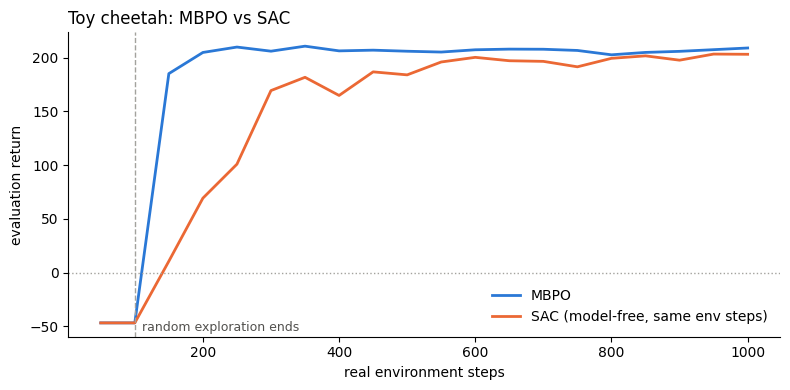

In [12]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(mbpo_curve[:, 0], mbpo_curve[:, 1], color="#2a78d6", lw=2, label="MBPO")
ax.plot(sac_curve[:, 0], sac_curve[:, 1], color="#eb6834", lw=2, label="SAC (model-free, same env steps)")
ax.axhline(0, color="#a3a29d", lw=1, ls=":")
ax.axvline(100, color="#a3a29d", lw=1, ls="--"); ax.text(110, ax.get_ylim()[0] + 5, "random exploration ends", color="#52514e", fontsize=9)
ax.set_xlabel("real environment steps"); ax.set_ylabel("evaluation return"); ax.set_title("Toy cheetah: MBPO vs SAC", loc="left")
for side in ("top", "right"): ax.spines[side].set_visible(False)
ax.legend(frameon=False); plt.tight_layout(); plt.show()

With the same real experience, MBPO reaches the good policy (push forward, return ≈ 220) much sooner, because each
real step feeds many SAC updates on model-generated data.

## 6. Results on HalfCheetah-v5

The full-scale run (`notebooks/MBPO_HalfCheetah_Kaggle.ipynb`, Kaggle GPU T4 x2) writes its plots to `results/`.
If they are present next to this notebook they are shown below.

In [13]:
import os
from IPython.display import Image, display
shown = False
for folder in ["results", "../results"]:
    for name in ["learning_curves.png", "model_loss.png"]:
        path = os.path.join(folder, name)
        if os.path.exists(path):
            display(Image(path)); shown = True
if not shown:
    print("No HalfCheetah results found yet - run the Kaggle notebook and put its results/ folder next to this notebook.")

No HalfCheetah results found yet - run the Kaggle notebook and put its results/ folder next to this notebook.
